## Classification using MLPs 

In [85]:
from scipy import stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.datasets import load_iris # dataset
from sklearn.model_selection import train_test_split, GridSearchCV, PredefinedSplit
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, roc_curve, auc
from sklearn.preprocessing import StandardScaler, label_binarize


import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import SGD


### Data Preparation

In [86]:
iris = load_iris(as_frame= True)
iris_df = pd.DataFrame(data= iris.data, columns=iris.feature_names)


In [87]:
X_values = iris.data
y_values = iris.target

In [88]:
print(f"Target names are: {str(iris.target_names[0]), str(iris.target_names[1]), str(iris.target_names[2])}")

Target names are: ('setosa', 'versicolor', 'virginica')


In [89]:
print(f"Feature names are: {str(X_values.columns[0]), str(X_values.columns[1]), str(X_values.columns[2])}")

Feature names are: ('sepal length (cm)', 'sepal width (cm)', 'petal length (cm)')


In [90]:
def data_prep(X_values, y_values, random_state = 123):
# initial split
    X_temp, X_test, y_temp, y_test = train_test_split(X_values,
                                                      y_values,
                                                      test_size = 0.2,
                                                      random_state=random_state)
    X_train, X_val, y_train, y_val = train_test_split(X_temp,
                                                      y_temp,
                                                      test_size=0.25,
                                                      random_state=random_state)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)
    return{
        'X_train': X_train,
        'X_val': X_val,
        'X_test': X_test,
        'y_train': y_train,
        'y_val': y_val,
        'y_test': y_test,
        'X_train_scaled': X_train_scaled,
        'X_val_scaled' : X_val_scaled,
        'X_test_scaled' : X_test_scaled,
        'scaler': scaler
    }

In [91]:
data_ = data_prep(X_values, y_values)
X_train = data_['X_train']
X_train_scaled = data_['X_train_scaled']
X_val_scaled = data_['X_val_scaled']
X_test_scaled = data_['X_test_scaled']
X_val = data_['X_val']
X_test = data_['X_test']
y_train = data_['y_train']
y_val = data_['y_val']
y_test = data_['y_test']

print('X_train sample: ', X_train.shape)
print('X_train_scaled sample: ', X_train_scaled.shape)
print('X_val_scaled sample: ', X_train_scaled.shape)
print('X_test_scaled sample: ', X_train_scaled.shape)
print('X_val sample: ', X_val.shape)
print('X_test sample: ', X_test.shape)
print('y_train sample: ', y_train.shape)
print('y_val sample: ', y_val.shape)
print('y_test sample: ', y_test.shape)

X_train sample:  (90, 4)
X_train_scaled sample:  (90, 4)
X_val_scaled sample:  (90, 4)
X_test_scaled sample:  (90, 4)
X_val sample:  (30, 4)
X_test sample:  (30, 4)
y_train sample:  (90,)
y_val sample:  (30,)
y_test sample:  (30,)


### Exploratory Data Analysis

In [92]:
X_train.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,90.000000,90.000000,90.000000,90.000000
mean,5.861111,3.031111,3.834444,1.227778
std,0.811808,0.421779,1.706179,0.733627
min,4.500000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.625000,0.400000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.000000,6.700000,2.500000


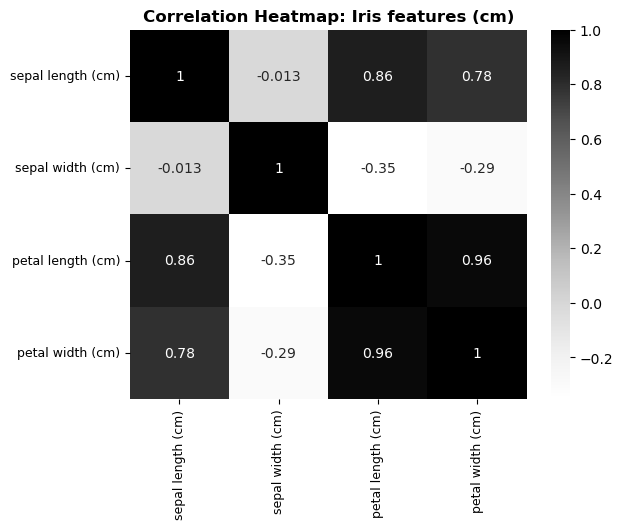

<Axes: title={'center': 'Correlation Heatmap: Iris features (cm)'}>

In [93]:
def corr_mat(X_tra):
    correlation_matrix = X_tra.corr(numeric_only =True)
    c_mat = sns.heatmap(correlation_matrix, cmap= "Greys", annot= True)
    plt.xticks(fontsize =9)
    plt.yticks(fontsize=9)
    plt.title("Correlation Heatmap: Iris features (cm)", fontsize=12, fontweight='bold')
    plt.show()
    return c_mat
corr_mat(X_train)

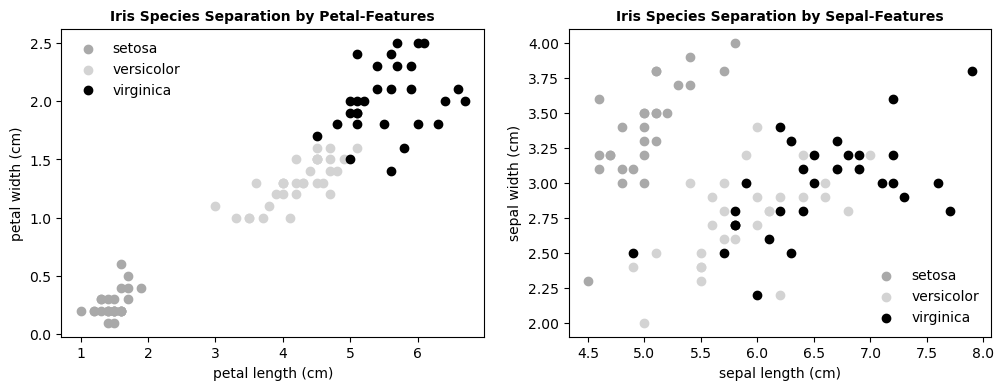

In [94]:
def plot_scatter(X_tra,y_tra):
    df_data = np.column_stack((X_tra, y_tra))
    y_tra.map({0.0:'setosa', 1.0:'versicolor', 2.0:'virginica'})
    df_colnames = list(iris.feature_names) + ['species']
    df_iris = pd.DataFrame(data =df_data, 
                           columns=df_colnames,  
                           copy = True)
    colors = {0.0: 'darkgrey', 1.0: 'lightgrey', 2.0: 'black'}
    species_names = {0.0: 'setosa', 1.0: 'versicolor', 2.0: 'virginica'}
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    for species, group in df_iris.groupby('species'):
        ax[0].scatter(group['petal length (cm)'], 
                      group['petal width (cm)'], 
                      color = colors[species], 
                      label = species_names[species])
    ax[0].set_xlabel('petal length (cm)')
    ax[0].set_ylabel('petal width (cm)')
    ax[0].set_title('Iris Species Separation by Petal-Features', 
              fontweight = 'bold', 
              fontsize = 10)
    ax[0].legend(frameon = False)
    for species, group in df_iris.groupby('species'):
        ax[1].scatter(group['sepal length (cm)'], 
                      group['sepal width (cm)'], 
                      color = colors[species], 
                      label = species_names[species])
    ax[1].set_xlabel('sepal length (cm)')
    ax[1].set_ylabel('sepal width (cm)')
    ax[1].set_title('Iris Species Separation by Sepal-Features', 
                    fontweight = 'bold', 
                    fontsize = 10)
    ax[1].legend(frameon = False)
    plt.show()

plot_scatter(X_train,y_train)


### Model: Neural Network

In [95]:
features = X_train.shape[1]

def create_model(features_):
    mlp_ = Sequential([
        Input(shape= (features_,)),

        Dense(64, activation = 'relu'),
    
        Dense(32, activation = "relu"),
    
        Dense(3, activation = "softmax")
    
    ])
    mlp_.compile(
        optimizer= SGD(learning_rate = 0.001),
        loss= 'sparse_categorical_crossentropy',
        metrics = ['accuracy']
    )
    return mlp_

In [96]:
mlp_model = create_model(features)

In [97]:
early_stopping = EarlyStopping(
    monitor = 'val_loss',
    min_delta = 0,
    patience = 15,
    restore_best_weights= True
)

In [98]:
EPOCHS = 100
BATCH_ = 16
mlp_history = mlp_model.fit(X_train_scaled, 
                        y_train,
                        validation_data = (X_val_scaled, y_val),
                        epochs = EPOCHS,
                        batch_size = BATCH_,
                        callbacks = [early_stopping],
                        verbose =1
                       )


Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - accuracy: 0.3778 - loss: 1.1920 - val_accuracy: 0.3333 - val_loss: 1.2321
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3778 - loss: 1.1863 - val_accuracy: 0.3333 - val_loss: 1.2252
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3778 - loss: 1.1805 - val_accuracy: 0.3333 - val_loss: 1.2182
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.3778 - loss: 1.1747 - val_accuracy: 0.3333 - val_loss: 1.2113
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3778 - loss: 1.1690 - val_accuracy: 0.3333 - val_loss: 1.2043
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.3778 - loss: 1.1632 - val_accuracy: 0.3333 - val_loss: 1.1979
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3778 - loss: 1.1577 - val_accuracy: 0.3333 - val_loss: 1.1916
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.3778 - loss: 1.1523 - val_accuracy: 0.3333 - val_loss

In [99]:
test_pred_probs = mlp_model.predict(X_test_scaled)
test_pred = np.argmax(test_pred_probs, axis = -1)
y_test = y_test.astype('int32')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step


In [100]:
test_pred_series = pd.Series(test_pred)

test_pred_output = test_pred_series.map({0.0:'setosa', 
                                         1.0:'versicolor', 
                                         2.0:'virginica'})

test_pred_output.value_counts()

setosa        13
virginica     12
versicolor     5
Name: count, dtype: int64

In [101]:
print(f"The species-specific probabilities for the first five samples are: \n{test_pred_probs[:5]}")

The species-specific probabilities for the first five samples are: 
[[0.17810595 0.4621011  0.35979295]
 [0.19665226 0.3078434  0.4955044 ]
 [0.17485774 0.35448265 0.47065952]
 [0.29359165 0.35896215 0.34744614]
 [0.49076706 0.313911   0.19532193]]


In [102]:
print(f"The species-specific predictions indices are: {test_pred}")

The species-specific predictions indices are: [1 2 2 1 0 2 1 0 0 1 2 0 1 2 2 2 0 0 2 0 0 2 0 2 0 0 0 2 2 0]


In [103]:
print(f"The species-specific predictions for the first five samples are: {iris.target_names[test_pred][:10]}")

The species-specific predictions for the first five samples are: ['versicolor' 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica'
 'versicolor' 'setosa' 'setosa' 'versicolor']


### Model Evaluation

In [104]:
test_accuracy = accuracy_score(y_test, test_pred)
print(f"Neural Network Test Accuracy: {test_accuracy * 100:.4f}%")

Neural Network Test Accuracy: 96.6667%


#### Parameters

In [105]:
mlp_history.params

{'verbose': 1, 'epochs': 100, 'steps': 6}

#### Cost Function & Accuracy

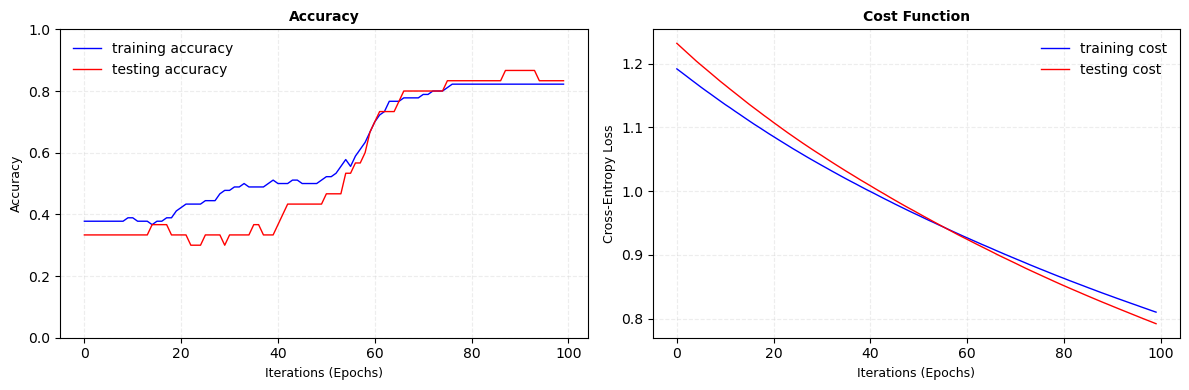

In [106]:
def plots(history_obj):
    plt.figure(figsize = (12, 4))
    plt.subplot(1,2,1)
    plt.plot(history_obj.history['accuracy'], 
             linewidth = 1.0, 
             label = "training accuracy", 
             color = 'blue')
    plt.plot(mlp_history.history['val_accuracy'], 
             linewidth = 1.0, 
             label = "testing accuracy", 
             color = 'red')
    plt.xlabel("Iterations (Epochs)", 
               fontsize = 9)
    plt.ylabel("Accuracy", 
               fontsize = 9)
    plt.ylim(0.0, 1.0)

    plt.legend(frameon=False)
    plt.title("Accuracy", 
              fontweight = 'bold', 
              fontsize = 10)
    plt.grid(True, color = 'lightgrey', 
             alpha = 0.4, 
             linestyle = '--')

    plt.subplot(1,2,2)
    plt.plot(mlp_history.history['loss'], 
             linewidth = 1.0, 
             label = "training cost", 
             color = 'blue')
    plt.plot(mlp_history.history['val_loss'], 
             linewidth = 1.0, 
             label = "testing cost", 
             color = 'red')
    plt.xlabel("Iterations (Epochs)", 
               fontsize = 9)
    plt.ylabel("Cross-Entropy Loss", 
               fontsize = 9)

    plt.legend(frameon = False)

    plt.title("Cost Function", 
              fontweight = 'bold', 
              fontsize = 10)
    plt.grid(True, color = 'lightgrey', 
             alpha = 0.4, 
             linestyle = '--')

    plt.tight_layout()
    plt.show()

plots(mlp_history)

In [107]:
print(f"The final training loss score for the Neural Network Model is : {str(round(mlp_history.history['loss'][-1],4))}")
print(f"The final testing loss score for the Neural Network Model is : {str(round(mlp_history.history['val_loss'][-1],4))}")

The final training loss score for the Neural Network Model is : 0.8101
The final testing loss score for the Neural Network Model is : 0.792


#### Model Performance

In [108]:
mlp_report = classification_report(y_test, test_pred, target_names=iris.target_names)
print(mlp_report)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       1.00      0.83      0.91         6
   virginica       0.92      1.00      0.96        11

    accuracy                           0.97        30
   macro avg       0.97      0.94      0.96        30
weighted avg       0.97      0.97      0.97        30



#### Confusion Matrix

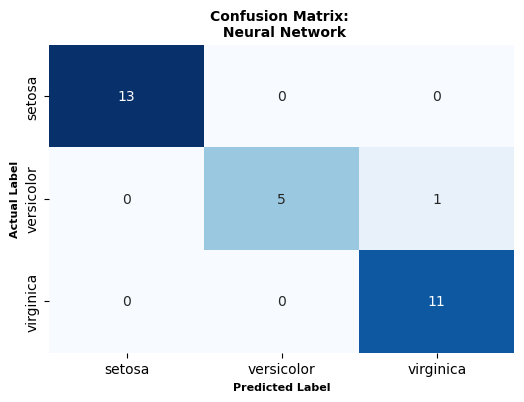

In [109]:
def create_cm(y_te, te_pred):
    mlp_cm = confusion_matrix(y_te, te_pred)
    plt.figure(figsize=(6,4))
    sns.heatmap(mlp_cm, 
               xticklabels = iris.target_names,
               yticklabels=iris.target_names, 
               cmap= 'Blues',
               annot=True,
               cbar = False)
    plt.title("Confusion Matrix: \n Neural Network", 
              fontsize = 10, 
              fontweight = 'bold')
    plt.xlabel("Predicted Label", 
               fontweight = 'bold', 
               fontsize = 8)
    plt.ylabel("Actual Label", 
               fontweight = 'bold', 
               fontsize = 8)
    plt.show()
create_cm(y_test, test_pred)

#### ROC AUC Curve

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step


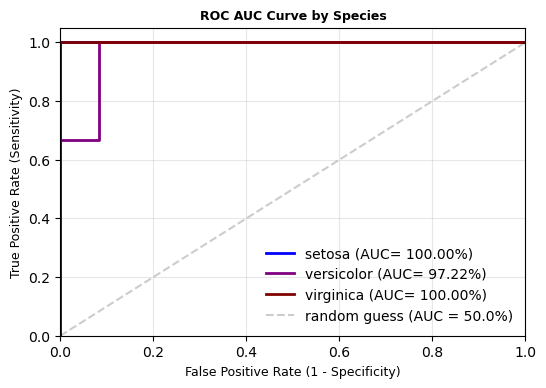

In [110]:
y_test_bin = label_binarize(y_test, classes = np.unique(y_test))
n_classes = y_test_bin.shape[1]

plt.figure(figsize=(6, 4))

colors= ['blue', 'purple', 'maroon']
# probability scores accounting for scaled predictors
y_prob = mlp_model.predict(X_test_scaled)


# ROC per class
for i in range(n_classes):
    fpr_, tpr_, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr_, tpr_)

    plt.plot(fpr_,
             tpr_, 
             color = colors[i],
             label = f'{iris.target_names[i]} (AUC= {roc_auc *100:.2f}%)',
             linewidth = 2)
plt.plot([0, 1], 
         [0, 1], 
         'k--', 
         lw= 1.5, 
         alpha = 0.2, 
         label='random guess (AUC = 50.0%)') # blac_k line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', 
           fontsize=9)
plt.ylabel('True Positive Rate (Sensitivity)', 
           fontsize=9)
plt.legend(loc="lower right", 
           frameon=False)
plt.title("ROC AUC Curve by Species", 
          fontweight = 'bold', 
          fontsize = 9)
plt.grid(True, alpha = 0.3)
plt.show()